# Notebook 06 — Dengue Case Forecasting

**RiskWeave Lanka | Model development**

## Objective
Forecast the **next dengue reporting period's case count** for each supported reporting area using historical dengue counts, calendar information, and historical weather summaries.

This notebook follows the approved proposal:
- Unit of analysis: area-week (the source's actual reporting period).
- Target: dengue cases in the following reporting period.
- Compare simple baselines with statistical / machine-learning models.
- Use chronological train/validation/test partitions.
- Evaluate with MAE and RMSE; do not assume a model is best before testing.

> **Geographic limitation:** the current analytical file has 25 reporting areas because the earlier ETL combined Ampara and Kalmune. Treat this as a documented working assumption until the surveillance geography is verified. This notebook does not silently change that decision.

> **Forecast-time limitation:** this first backtest assumes the latest completed dengue reporting period and its weather summary are available at the forecast origin. If dengue publication is delayed, the operational model must shift dengue and weather inputs further back to match the real publication schedule. We will make that availability assumption explicit when interpreting results.

> **Weather source note:** the current project weather file was collected from Open-Meteo ERA5, not NASA POWER as named in the proposal. Keep this deviation documented; do not describe the current data as NASA POWER data.


## 1. Import libraries

In [1]:
from pathlib import Path
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.linear_model import PoissonRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 160)

RANDOM_STATE = 42
print("Libraries imported.")

Libraries imported.


## 2. Set project paths and load the combined dataset

In [2]:
cwd = Path.cwd()
if cwd.name == "notebooks":
    PROJECT_ROOT = cwd.parent
elif (cwd / "data").exists():
    PROJECT_ROOT = cwd
else:
    raise FileNotFoundError(
        "Could not identify the RiskWeave project root. "
        "Open this notebook from the RiskWeave project or its notebooks folder."
    )

DATA_PATH = PROJECT_ROOT / "data" / "processed" / "dengue_weather_weekly_25_districts.csv"
OUTPUT_DIR = PROJECT_ROOT / "outputs" / "forecasting"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

if not DATA_PATH.exists():
    raise FileNotFoundError(f"Dataset not found: {DATA_PATH}")

df = pd.read_csv(DATA_PATH)
print("Loaded:", DATA_PATH)
print("Shape:", df.shape)
display(df.head())

Loaded: c:\Users\Nethmi\Documents\GitHub\RiskWeave\data\processed\dengue_weather_weekly_25_districts.csv
Shape: (24775, 27)


,district_key,week_start,week_end,dengue_cases,reporting_period_days,source_reporting_rows,source_areas,weather_days_observed,weather_days_expected,weather_days_complete,precipitation_sum,precipitation_hours,shortwave_radiation_sum,et0_fao_evapotranspiration,precipitation_mean_daily,shortwave_radiation_mean_daily,temperature_2m_mean,temperature_2m_max,temperature_2m_min,relative_humidity_2m_mean,relative_humidity_2m_max,relative_humidity_2m_min,dew_point_2m_mean,wind_speed_10m_mean,wind_speed_10m_max,cloud_cover_mean,wind_direction_10m_dominant
0,ampara,2006-12-23,2006-12-29,0,7,2,Ampara | Kalmune,7,7,True,15.3,60.0,97.86,23.42,2.185714,13.980000,25.342857,27.528571,23.571429,79.857143,87.285714,70.571429,21.471429,15.685714,21.085714,89.142857,8.574025
1,ampara,2006-12-30,2007-01-05,0,7,2,Ampara | Kalmune,7,7,True,0.0,0.0,142.30,32.75,0.000000,20.328571,24.600000,28.042857,21.385714,71.142857,82.428571,57.000000,18.885714,14.485714,19.614286,59.428571,358.285579
2,ampara,2007-01-06,2007-01-12,0,7,2,Ampara | Kalmune,7,7,True,77.2,115.0,90.53,19.61,11.028571,12.932857,24.885714,26.957143,23.271429,86.285714,92.285714,78.714286,22.285714,14.842857,18.828571,78.285714,20.694632
3,ampara,2007-01-13,2007-01-19,0,7,2,Ampara | Kalmune,7,7,True,7.3,33.0,118.19,25.32,1.042857,16.884286,25.514286,27.728571,23.571429,83.142857,89.714286,74.571429,22.357143,17.114286,23.000000,77.857143,11.275426
4,ampara,2007-01-20,2007-01-26,0,7,2,Ampara | Kalmune,7,7,True,30.1,28.0,119.23,27.83,4.300000,17.032857,25.085714,27.814286,22.742857,76.714286,85.142857,66.142857,20.600000,15.514286,20.385714,71.142857,7.286656


## 3. Validate the dataset schema

In [3]:
required_cols = ["district_key", "week_start", "week_end", "dengue_cases"]
missing_cols = [c for c in required_cols if c not in df.columns]
if missing_cols:
    raise ValueError(f"Required columns are missing: {missing_cols}")

df["week_start"] = pd.to_datetime(df["week_start"], errors="coerce")
df["week_end"] = pd.to_datetime(df["week_end"], errors="coerce")
df["dengue_cases"] = pd.to_numeric(df["dengue_cases"], errors="coerce")

if df[required_cols].isna().any().any():
    raise ValueError("Required fields contain missing or invalid values. Resolve these before modelling.")
if (df["dengue_cases"] < 0).any():
    raise ValueError("Negative dengue case counts found.")
if df.duplicated(["district_key", "week_start"]).any():
    raise ValueError("Duplicate district-week records found.")

df = df.sort_values(["district_key", "week_start"]).reset_index(drop=True)

print("Rows:", len(df))
print("Reporting areas:", df["district_key"].nunique())
print("Period range:", df["week_start"].min().date(), "to", df["week_end"].max().date())
print("Duplicate area-period keys:", df.duplicated(["district_key", "week_start"]).sum())
print("Missing values in required fields:", int(df[required_cols].isna().sum().sum()))
display(df[required_cols].describe(include="all"))

Rows: 24775
Reporting areas: 25
Period range: 2006-12-23 to 2025-12-19
Duplicate area-period keys: 0
Missing values in required fields: 0


,district_key,week_start,week_end,dengue_cases
count,24775,24775,24775,24775.000000
unique,25,NaN,NaN,NaN
top,ampara,NaN,NaN,NaN
freq,991,NaN,NaN,NaN
mean,NaN,2016-06-18 00:07:15.923309568,2016-06-24 00:07:15.923309568,32.414692
min,NaN,2006-12-23 00:00:00,2006-12-29 00:00:00,0.000000
25%,NaN,2011-09-17 00:00:00,2011-09-23 00:00:00,2.000000
50%,NaN,2016-06-18 00:00:00,2016-06-24 00:00:00,10.000000
75%,NaN,2021-03-20 00:00:00,2021-03-26 00:00:00,30.000000
max,NaN,2025-12-13 00:00:00,2025-12-19 00:00:00,2631.000000


## 4. Identify weather predictors

We select environmental measurements only. Administrative completeness fields such as `reporting_period_days`, `source_reporting_rows`, `weather_days_observed`, and `weather_days_expected` are **not** model predictors. They describe the construction or quality of the dataset.

`precipitation_sum` and `rain_sum` are duplicates in the current source; use at most one. Wind direction is circular, so this first baseline excludes it rather than treating degrees as a straight-line measurement.

In [4]:
candidate_weather = [
    "precipitation_mean_daily",
    "precipitation_sum",
    "precipitation_hours",
    "temperature_2m_mean",
    "temperature_2m_max",
    "temperature_2m_min",
    "relative_humidity_2m_mean",
    "relative_humidity_2m_max",
    "relative_humidity_2m_min",
    "dew_point_2m_mean",
    "wind_speed_10m_mean",
    "wind_speed_10m_max",
    "cloud_cover_mean",
    "shortwave_radiation_mean_daily",
    "et0_fao_evapotranspiration",
]

weather_cols = [c for c in candidate_weather if c in df.columns]

# Avoid retaining both total precipitation and its daily-normalized version.
# The normalized version is preferred because source reporting periods are not all exactly 7 days.
if "precipitation_mean_daily" in weather_cols and "precipitation_sum" in weather_cols:
    weather_cols.remove("precipitation_sum")
if "shortwave_radiation_mean_daily" in weather_cols and "shortwave_radiation_sum" in df.columns:
    pass

print("Weather predictors found:")
print(weather_cols)
not_found = [c for c in candidate_weather if c not in df.columns]
print("\nCandidate columns not present (not necessarily an error):", not_found)

Weather predictors found:
['precipitation_mean_daily', 'precipitation_hours', 'temperature_2m_mean', 'temperature_2m_max', 'temperature_2m_min', 'relative_humidity_2m_mean', 'relative_humidity_2m_max', 'relative_humidity_2m_min', 'dew_point_2m_mean', 'wind_speed_10m_mean', 'wind_speed_10m_max', 'cloud_cover_mean', 'shortwave_radiation_mean_daily', 'et0_fao_evapotranspiration']

Candidate columns not present (not necessarily an error): []


## 5. Create leakage-aware forecasting features

**Forecasting definition**

- Forecast origin: the latest **completed** reporting period, denoted period *t*.
- Forecast target: dengue cases in the **next** reporting period, *t+1*.
- Dengue history includes the current completed period and earlier periods.
- Weather predictors include summaries from the current completed period (`lag0`) and the previous completed period (`lag1`).
- The four-period mean includes the current period and the three periods before it.
- The approximate previous-year target-period comparison uses 51 reporting-record lags: when predicting *t+1*, lag 51 is approximately the corresponding period one year earlier if the series has a regular 52-period annual cadence.

**Important limitation:** weekly or reporting-period aggregates cannot identify an exact 4–5-day biological delay. The lagged weather variables are candidate predictors, not proof of a specific dengue incubation or transmission delay. `lag0` weather is valid only if the complete weather summary for period *t* is available when the forecast is issued.

All shifts are calculated separately within each reporting area after sorting by date. The target is shifted backwards from the next row; no future target information is included in the predictors.


In [5]:
# Section 5 — Leakage-aware forecasting features
# Forecast origin: latest completed reporting period (t)
# Forecast target: next reporting period (t+1)

df = df.sort_values(
    ["district_key", "week_start"]
).reset_index(drop=True)

grouped = df.groupby("district_key", sort=False)

# Dengue history: previous periods.
for lag in [1, 2, 3, 4, 51, 52]:
    df[f"dengue_lag_{lag}"] = grouped["dengue_cases"].shift(lag)

# Latest completed-period dengue count (period t).
df["dengue_current_period"] = df["dengue_cases"]

# Mean of current period and previous three reporting periods.
df["dengue_rolling_mean_4"] = (
    df.groupby("district_key", sort=False)["dengue_cases"]
      .transform(lambda s: s.rolling(window=4, min_periods=2).mean())
)

# Weather summaries from completed reporting periods:
# lag0 = current completed period (t); lag1 = preceding period (t-1).
for col in weather_cols:
    df[f"{col}_lag0"] = (
        df.groupby("district_key", sort=False)[col].shift(0)
    )
    df[f"{col}_lag1"] = (
        df.groupby("district_key", sort=False)[col].shift(1)
    )

# Calendar features based on forecast-origin period t.
week_of_year = df["week_start"].dt.isocalendar().week.astype(int)
df["month"] = df["week_start"].dt.month
df["week_sin"] = np.sin(2 * np.pi * week_of_year / 52.1775)
df["week_cos"] = np.cos(2 * np.pi * week_of_year / 52.1775)

# Target is the next reporting period's dengue count and date.
df["target_next_cases"] = (
    df.groupby("district_key", sort=False)["dengue_cases"].shift(-1)
)
df["target_week_start"] = (
    df.groupby("district_key", sort=False)["week_start"].shift(-1)
)

# Remove only rows without a next-period target.
# Early missing lag features are retained and imputed within training pipelines.
model_df = df.dropna(
    subset=["target_next_cases", "target_week_start"]
).copy()
model_df["target_next_cases"] = model_df["target_next_cases"].astype(float)

print("Forecasting features created.")
print("Forecast origin: latest completed reporting period")
print("Target: next reporting period")
print("Rows:", len(model_df))

display(
    model_df[
        [
            "district_key", "week_start", "target_week_start",
            "dengue_current_period", "dengue_lag_1",
            "dengue_lag_4", "dengue_lag_51",
            "target_next_cases"
        ]
    ].head(10)
)

# Audit reporting-period cadence; lag 1 means the previous record,
# and is not guaranteed to mean exactly seven calendar days.
period_gaps = (
    df.groupby("district_key", sort=False)["week_start"]
      .diff().dt.days
      .dropna()
)
print("\nReporting date-gap counts (days):")
display(period_gaps.value_counts().sort_index().rename_axis("days_between_records").to_frame("count"))


Forecasting features created.
Forecast origin: latest completed reporting period
Target: next reporting period
Rows: 24750


,district_key,week_start,target_week_start,dengue_current_period,dengue_lag_1,dengue_lag_4,dengue_lag_51,target_next_cases
0,ampara,2006-12-23,2006-12-30,0,NaN,NaN,NaN,0.0
1,ampara,2006-12-30,2007-01-06,0,0.0,NaN,NaN,0.0
2,ampara,2007-01-06,2007-01-13,0,0.0,NaN,NaN,0.0
3,ampara,2007-01-13,2007-01-20,0,0.0,NaN,NaN,0.0
4,ampara,2007-01-20,2007-01-27,0,0.0,0.0,NaN,0.0
5,ampara,2007-01-27,2007-02-03,0,0.0,0.0,NaN,0.0
6,ampara,2007-02-03,2007-02-10,0,0.0,0.0,NaN,0.0
7,ampara,2007-02-10,2007-02-17,0,0.0,0.0,NaN,0.0
8,ampara,2007-02-17,2007-02-24,0,0.0,0.0,NaN,1.0
9,ampara,2007-02-24,2007-03-03,1,0.0,0.0,NaN,0.0



Reporting date-gap counts (days):


,count
days_between_records,
6.0,25
7.0,24700
8.0,25


## 6. Define features and chronological train/validation/test splits

The predictors are constructed from information available at the forecast origin:

- Current completed-period dengue count and previous dengue counts.
- A four-reporting-period mean including the current period.
- Calendar features.
- Weather summaries from the current and previous completed reporting periods.

The target-date split is chronological: earliest 70% of target periods for training, next 15% for validation, and latest 15% for final testing. All reporting areas belonging to the same target date remain in the same split. Imputation and scaling are fitted inside each model pipeline using training data only.


In [6]:
# Section 6 — Features and chronological split

feature_cols = [
    "district_key",

    # Dengue history available at forecast origin
    "dengue_current_period",
    "dengue_lag_1",
    "dengue_lag_2",
    "dengue_lag_3",
    "dengue_lag_4",
    "dengue_lag_51",
    "dengue_lag_52",
    "dengue_rolling_mean_4",

    # Calendar
    "month",
    "week_sin",
    "week_cos",
]

# Environmental predictors from current and previous completed periods.
for col in weather_cols:
    feature_cols.extend([f"{col}_lag0", f"{col}_lag1"])

# Retain only columns that were actually created.
feature_cols = [c for c in feature_cols if c in model_df.columns]

if "dengue_current_period" not in feature_cols:
    raise ValueError("The current-period dengue feature was not created.")
if not weather_cols:
    raise ValueError("No expected weather predictors were found. Check Section 4.")

print("Number of predictors:", len(feature_cols))
print("\nSelected predictors:")
print(feature_cols)

unique_target_dates = np.array(sorted(model_df["target_week_start"].unique()))
n_dates = len(unique_target_dates)

if n_dates < 10:
    raise ValueError("Too few unique target periods for a 70/15/15 chronological split.")

train_end = unique_target_dates[int(n_dates * 0.70) - 1]
validation_end = unique_target_dates[int(n_dates * 0.85) - 1]

train = model_df[model_df["target_week_start"] <= train_end].copy()
valid = model_df[
    (model_df["target_week_start"] > train_end) &
    (model_df["target_week_start"] <= validation_end)
].copy()
test = model_df[model_df["target_week_start"] > validation_end].copy()

print("\nUnique target periods:", n_dates)
print("Train:", train["target_week_start"].min().date(), "to",
      train["target_week_start"].max().date(), "| rows:", len(train))
print("Validation:", valid["target_week_start"].min().date(), "to",
      valid["target_week_start"].max().date(), "| rows:", len(valid))
print("Test:", test["target_week_start"].min().date(), "to",
      test["target_week_start"].max().date(), "| rows:", len(test))

assert train["target_week_start"].max() < valid["target_week_start"].min()
assert valid["target_week_start"].max() < test["target_week_start"].min()

X_train, y_train = train[feature_cols], train["target_next_cases"]
X_valid, y_valid = valid[feature_cols], valid["target_next_cases"]
X_test, y_test = test[feature_cols], test["target_next_cases"]

categorical_features = ["district_key"]
numeric_features = [c for c in feature_cols if c not in categorical_features]

assert set(numeric_features + categorical_features) == set(feature_cols)
print("\nNumber of numerical features:", len(numeric_features))
print("Number of categorical features:", len(categorical_features))


Number of predictors: 40

Selected predictors:
['district_key', 'dengue_current_period', 'dengue_lag_1', 'dengue_lag_2', 'dengue_lag_3', 'dengue_lag_4', 'dengue_lag_51', 'dengue_lag_52', 'dengue_rolling_mean_4', 'month', 'week_sin', 'week_cos', 'precipitation_mean_daily_lag0', 'precipitation_mean_daily_lag1', 'precipitation_hours_lag0', 'precipitation_hours_lag1', 'temperature_2m_mean_lag0', 'temperature_2m_mean_lag1', 'temperature_2m_max_lag0', 'temperature_2m_max_lag1', 'temperature_2m_min_lag0', 'temperature_2m_min_lag1', 'relative_humidity_2m_mean_lag0', 'relative_humidity_2m_mean_lag1', 'relative_humidity_2m_max_lag0', 'relative_humidity_2m_max_lag1', 'relative_humidity_2m_min_lag0', 'relative_humidity_2m_min_lag1', 'dew_point_2m_mean_lag0', 'dew_point_2m_mean_lag1', 'wind_speed_10m_mean_lag0', 'wind_speed_10m_mean_lag1', 'wind_speed_10m_max_lag0', 'wind_speed_10m_max_lag1', 'cloud_cover_mean_lag0', 'cloud_cover_mean_lag1', 'shortwave_radiation_mean_daily_lag0', 'shortwave_radiati

## 7. Establish simple forecasting baselines

The baselines are evaluated on the same validation rows so that their MAE/RMSE comparisons are fair:

1. **Last observed period:** use the dengue count from the latest completed period.
2. **Previous 4-period mean:** use the mean of the current and previous three reporting periods.
3. **Previous-year same-period (51 lags):** use the count approximately one year before the target period.

The 51-lag seasonal comparison is approximate. It assumes a regular reporting cadence and should not be interpreted as exact calendar-week matching.


In [7]:
# Section 7 — Forecasting baselines

def score_predictions(y_true, predictions):
    predictions = np.maximum(0, np.asarray(predictions, dtype=float))
    return {
        "MAE": mean_absolute_error(y_true, predictions),
        "RMSE": np.sqrt(mean_squared_error(y_true, predictions)),
    }

# Ensure all baselines are evaluated on exactly the same validation observations.
if valid["dengue_lag_51"].isna().any():
    raise ValueError(
        "The 51-period seasonal baseline has missing values in validation. "
        "Do not compare it against other baselines on a different subset. "
        "Review the reporting history or define a common evaluation subset."
    )

baseline_results = [
    {
        "model": "Last observed period",
        **score_predictions(
            y_valid,
            valid["dengue_current_period"].values
        )
    },
    {
        "model": "Previous 4-period mean",
        **score_predictions(
            y_valid,
            valid["dengue_rolling_mean_4"].values
        )
    },
    {
        "model": "Previous-year same-period (51 lags)",
        **score_predictions(
            y_valid,
            valid["dengue_lag_51"].values
        )
    },
]

baseline_validation = (
    pd.DataFrame(baseline_results)
      .sort_values("MAE")
      .reset_index(drop=True)
)
display(baseline_validation)

baseline_validation.to_csv(
    OUTPUT_DIR / "baseline_validation_metrics.csv",
    index=False
)


,model,MAE,RMSE
0,Last observed period,8.742973,19.697942
1,Previous 4-period mean,8.932838,19.260517
2,Previous-year same-period (51 lags),37.020270,87.983593


## 8. Build preprocessing and candidate models

We compare the approved candidate model families:

1. **Poisson regression** — a count-oriented statistical model.
2. **Random Forest** — a nonlinear tree-ensemble model.
3. **Histogram Gradient Boosting** — a boosting-based tree model.

Numerical missing values are imputed using medians learned from the training split. District is one-hot encoded. The one-hot encoder is configured to produce dense output so it is compatible with Histogram Gradient Boosting in scikit-learn versions that do not accept sparse input.

All preprocessing is inside the pipeline, preventing validation/test information from being used to fit imputers or scalers.


In [8]:
# Section 8 — Preprocessing and candidate models

numeric_preprocess = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

categorical_preprocess = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    )),
])

# All column names here are drawn from the current feature_cols list.
preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", numeric_preprocess, numeric_features),
        ("categorical", categorical_preprocess, categorical_features),
    ],
    remainder="drop"
)

models = {
    "Poisson regression": PoissonRegressor(alpha=0.1, max_iter=1000),
    "Random Forest": RandomForestRegressor(
        n_estimators=300,
        min_samples_leaf=3,
        random_state=RANDOM_STATE,
        n_jobs=-1
    ),
    "Histogram Gradient Boosting": HistGradientBoostingRegressor(
        max_iter=200,
        learning_rate=0.08,
        max_leaf_nodes=20,
        l2_regularization=1.0,
        random_state=RANDOM_STATE
    ),
}

# Preflight: catch stale or misspelled preprocessing columns before model fitting.
preprocessor_columns = numeric_features + categorical_features
missing_preprocessor_columns = [
    c for c in preprocessor_columns if c not in X_train.columns
]
if missing_preprocessor_columns:
    raise ValueError(
        f"Preprocessor refers to columns absent from X_train: "
        f"{missing_preprocessor_columns}"
    )

fitted_models = {}
validation_rows = []

for name, estimator in models.items():
    pipe = Pipeline(steps=[
        ("preprocess", preprocessor),
        ("model", estimator),
    ])
    pipe.fit(X_train, y_train)
    pred = np.maximum(0, pipe.predict(X_valid))
    fitted_models[name] = pipe
    validation_rows.append({
        "model": name,
        **score_predictions(y_valid, pred)
    })

model_validation = pd.DataFrame(validation_rows)

validation_comparison = (
    pd.concat([baseline_validation, model_validation], ignore_index=True)
      .sort_values("MAE")
      .reset_index(drop=True)
)

display(validation_comparison)
validation_comparison.to_csv(
    OUTPUT_DIR / "model_validation_metrics.csv",
    index=False
)


,model,MAE,RMSE
0,Histogram Gradient Boosting,8.705167,18.578114
1,Last observed period,8.742973,19.697942
2,Random Forest,8.755781,18.996141
3,Previous 4-period mean,8.932838,19.260517
4,Poisson regression,19.333521,29.432193
5,Previous-year same-period (51 lags),37.020270,87.983593


## 9. Select a model using validation results

Choose the model with the lowest validation MAE as the primary candidate. This is a selection rule, not proof that it will generalize. The final test set remains untouched until this choice is made.

If a simple baseline beats the machine-learning models, that is a valid and important result. Do not select a more complex model just because it is more sophisticated.

In [9]:
best_model_name = validation_comparison.iloc[0]["model"]
print("Best validation result:", best_model_name)

if best_model_name in fitted_models:
    selected_model = fitted_models[best_model_name]
    selected_model_type = "machine_learning"
else:
    selected_model = None
    selected_model_type = "baseline"

print("Selected model type:", selected_model_type)

Best validation result: Histogram Gradient Boosting
Selected model type: machine_learning


## 10. Final test evaluation

Select the model using validation MAE only. Then refit the selected machine-learning pipeline on training + validation data and evaluate once on the untouched final test period.

If a baseline is selected, calculate its predictions using the matching forecast-origin feature. The final test set is not used for model selection or hyperparameter tuning.


In [10]:
# Section 10 — Final test evaluation

train_valid = pd.concat([train, valid], ignore_index=True)
X_train_valid = train_valid[feature_cols]
y_train_valid = train_valid["target_next_cases"]

if selected_model_type == "machine_learning":
    final_model = Pipeline(steps=[
        ("preprocess", preprocessor),
        ("model", models[best_model_name]),
    ])
    final_model.fit(X_train_valid, y_train_valid)
    test_predictions = np.maximum(0, final_model.predict(X_test))

else:
    final_model = None

    if best_model_name == "Last observed period":
        test_predictions = np.maximum(
            0,
            test["dengue_current_period"].values
        )

    elif best_model_name == "Previous 4-period mean":
        test_predictions = np.maximum(
            0,
            test["dengue_rolling_mean_4"].values
        )

    elif best_model_name == "Previous-year same-period (51 lags)":
        if test["dengue_lag_51"].isna().any():
            raise ValueError(
                "The selected 51-lag seasonal baseline has missing test values."
            )
        test_predictions = np.maximum(
            0,
            test["dengue_lag_51"].values
        )

    else:
        raise ValueError(
            f"Unrecognized selected baseline: {best_model_name}"
        )

test_metrics = pd.DataFrame([{
    "selected_model": best_model_name,
    **score_predictions(y_test, test_predictions)
}])
display(test_metrics)

test_metrics.to_csv(
    OUTPUT_DIR / "final_test_metrics.csv",
    index=False
)

test_output = test[
    [
        "district_key", "week_start",
        "target_week_start", "target_next_cases"
    ]
].copy()
test_output["predicted_cases"] = test_predictions
test_output["absolute_error"] = np.abs(
    test_output["target_next_cases"] - test_output["predicted_cases"]
)

test_output.to_csv(
    OUTPUT_DIR / "test_predictions.csv",
    index=False
)
display(test_output.head(10))


,selected_model,MAE,RMSE
0,Histogram Gradient Boosting,12.537762,29.769481


,district_key,week_start,target_week_start,target_next_cases,predicted_cases,absolute_error
841,ampara,2023-02-04,2023-02-11,55.0,77.713142,22.713142
842,ampara,2023-02-11,2023-02-18,42.0,60.655098,18.655098
843,ampara,2023-02-18,2023-02-25,58.0,46.013524,11.986476
844,ampara,2023-02-25,2023-03-04,33.0,50.477297,17.477297
845,ampara,2023-03-04,2023-03-11,31.0,39.922015,8.922015
846,ampara,2023-03-11,2023-03-18,26.0,33.272548,7.272548
847,ampara,2023-03-18,2023-03-25,41.0,27.201367,13.798633
848,ampara,2023-03-25,2023-04-01,47.0,34.874568,12.125432
849,ampara,2023-04-01,2023-04-08,16.0,38.370120,22.370120
850,ampara,2023-04-08,2023-04-15,71.0,29.497050,41.502950


## 11. Controlled weather-feature ablation experiment

This experiment tests whether adding weather predictors improves the same Histogram Gradient Boosting model compared with using dengue history and calendar predictors alone.

Two feature sets are compared:

1. **Without weather:** district, dengue-history, and calendar predictors.
2. **With weather:** the complete feature set, including current and previous completed-period weather summaries.

Both models use the same chronological training, validation, and test periods and the same model hyperparameters. Preprocessing is fitted only on the relevant training data. Validation metrics are reported for comparison; the final test period remains reserved for evaluation.

A lower MAE/RMSE indicates better performance. A small difference should be interpreted cautiously and does not establish causality.


In [11]:
# Section 11 — Controlled weather-feature ablation

from sklearn.base import clone

# Weather predictors are the engineered columns ending in lag0 or lag1.
weather_feature_cols = [
    c for c in feature_cols
    if c.endswith("_lag0") or c.endswith("_lag1")
]

# All remaining predictors represent dengue history, calendar, or district.
no_weather_feature_cols = [
    c for c in feature_cols
    if c not in weather_feature_cols
]

if not weather_feature_cols:
    raise ValueError(
        "No weather lag features were detected. Check Sections 4–6."
    )

print("Predictors without weather:", len(no_weather_feature_cols))
print("Weather predictors added:", len(weather_feature_cols))
print("\nWeather features:")
print(weather_feature_cols)

def build_ablation_pipeline(selected_features):
    # Derive preprocessing columns from the feature set being tested.
    cat_cols = [
        c for c in selected_features
        if c == "district_key"
    ]
    num_cols = [
        c for c in selected_features
        if c not in cat_cols
    ]

    numeric_transformer = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ])

    transformers = [
        ("numeric", numeric_transformer, num_cols)
    ]

    if cat_cols:
        categorical_transformer = Pipeline(steps=[
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            )),
        ])
        transformers.append(
            ("categorical", categorical_transformer, cat_cols)
        )

    ablation_preprocessor = ColumnTransformer(
        transformers=transformers,
        remainder="drop"
    )

    # Clone the already-defined HGB estimator so both experiments
    # use exactly the same model family and hyperparameters.
    return Pipeline(steps=[
        ("preprocess", ablation_preprocessor),
        ("model", clone(models["Histogram Gradient Boosting"])),
    ])


ablation_feature_sets = {
    "Without weather": no_weather_feature_cols,
    "With weather": feature_cols,
}

ablation_pipelines = {}
ablation_rows = []

# Validation comparison: fit on training data only.
for experiment_name, selected_features in ablation_feature_sets.items():
    pipeline = build_ablation_pipeline(selected_features)

    pipeline.fit(
        train[selected_features],
        y_train
    )

    validation_predictions = np.maximum(
        0,
        pipeline.predict(valid[selected_features])
    )

    ablation_pipelines[experiment_name] = pipeline

    ablation_rows.append({
        "experiment": experiment_name,
        "evaluation": "validation",
        **score_predictions(y_valid, validation_predictions)
    })

# Final test comparison: refit each experiment on train + validation.
# The test set is used only for final evaluation.
for experiment_name, selected_features in ablation_feature_sets.items():
    final_ablation_pipeline = build_ablation_pipeline(selected_features)

    final_ablation_pipeline.fit(
        train_valid[selected_features],
        y_train_valid
    )

    test_ablation_predictions = np.maximum(
        0,
        final_ablation_pipeline.predict(test[selected_features])
    )

    ablation_rows.append({
        "experiment": experiment_name,
        "evaluation": "test",
        **score_predictions(y_test, test_ablation_predictions)
    })

    # Keep the full-feature test predictions for an optional
    # consistency check against the selected final model.
    if experiment_name == "With weather":
        hgb_with_weather_test_predictions = test_ablation_predictions

weather_ablation_results = (
    pd.DataFrame(ablation_rows)
      .sort_values(["evaluation", "MAE"])
      .reset_index(drop=True)
)

display(weather_ablation_results)

weather_ablation_results.to_csv(
    OUTPUT_DIR / "weather_ablation_comparison.csv",
    index=False
)

# Summarize the change in test metrics when weather is added.
test_ablation = weather_ablation_results[
    weather_ablation_results["evaluation"] == "test"
].set_index("experiment")

mae_without_weather = test_ablation.loc["Without weather", "MAE"]
mae_with_weather = test_ablation.loc["With weather", "MAE"]
rmse_without_weather = test_ablation.loc["Without weather", "RMSE"]
rmse_with_weather = test_ablation.loc["With weather", "RMSE"]

print("\nTest-set change after adding weather:")
print("MAE change (with - without):", round(
    mae_with_weather - mae_without_weather, 4
))
print("RMSE change (with - without):", round(
    rmse_with_weather - rmse_without_weather, 4
))

if mae_with_weather < mae_without_weather and rmse_with_weather < rmse_without_weather:
    print("Interpretation: weather features improved both test metrics in this experiment.")
elif mae_with_weather < mae_without_weather:
    print("Interpretation: weather features improved test MAE, but not both metrics.")
elif rmse_with_weather < rmse_without_weather:
    print("Interpretation: weather features improved test RMSE, but not both metrics.")
else:
    print("Interpretation: weather features did not improve either test metric in this experiment.")


Predictors without weather: 12
Weather predictors added: 28

Weather features:
['precipitation_mean_daily_lag0', 'precipitation_mean_daily_lag1', 'precipitation_hours_lag0', 'precipitation_hours_lag1', 'temperature_2m_mean_lag0', 'temperature_2m_mean_lag1', 'temperature_2m_max_lag0', 'temperature_2m_max_lag1', 'temperature_2m_min_lag0', 'temperature_2m_min_lag1', 'relative_humidity_2m_mean_lag0', 'relative_humidity_2m_mean_lag1', 'relative_humidity_2m_max_lag0', 'relative_humidity_2m_max_lag1', 'relative_humidity_2m_min_lag0', 'relative_humidity_2m_min_lag1', 'dew_point_2m_mean_lag0', 'dew_point_2m_mean_lag1', 'wind_speed_10m_mean_lag0', 'wind_speed_10m_mean_lag1', 'wind_speed_10m_max_lag0', 'wind_speed_10m_max_lag1', 'cloud_cover_mean_lag0', 'cloud_cover_mean_lag1', 'shortwave_radiation_mean_daily_lag0', 'shortwave_radiation_mean_daily_lag1', 'et0_fao_evapotranspiration_lag0', 'et0_fao_evapotranspiration_lag1']


,experiment,evaluation,MAE,RMSE
0,Without weather,test,12.384966,28.872096
1,With weather,test,12.537762,29.769481
2,Without weather,validation,8.609656,18.427300
3,With weather,validation,8.705167,18.578114



Test-set change after adding weather:
MAE change (with - without): 0.1528
RMSE change (with - without): 0.8974
Interpretation: weather features did not improve either test metric in this experiment.


In [15]:
# Select the preferred forecasting feature set
# Based on the weather ablation experiment.

selected_feature_set = "Without weather"

final_feature_cols = no_weather_feature_cols.copy()

print("Selected feature set:", selected_feature_set)
print("Number of selected predictors:", len(final_feature_cols))
print("\nSelected predictors:")
print(final_feature_cols)

Selected feature set: Without weather
Number of selected predictors: 12

Selected predictors:
['district_key', 'dengue_current_period', 'dengue_lag_1', 'dengue_lag_2', 'dengue_lag_3', 'dengue_lag_4', 'dengue_lag_51', 'dengue_lag_52', 'dengue_rolling_mean_4', 'month', 'week_sin', 'week_cos']


In [16]:
# Prepare data using the selected no-weather features

X_train_final = train[final_feature_cols]
X_valid_final = valid[final_feature_cols]
X_test_final = test[final_feature_cols]

X_train_valid_final = train_valid[final_feature_cols]

print("Training shape:", X_train_final.shape)
print("Validation shape:", X_valid_final.shape)
print("Testing shape:", X_test_final.shape)

assert list(X_train_final.columns) == final_feature_cols
assert list(X_test_final.columns) == final_feature_cols

Training shape: (17325, 12)
Validation shape: (3700, 12)
Testing shape: (3725, 12)


In [17]:
# Train final Histogram Gradient Boosting model
# using dengue history and calendar predictors only.

from sklearn.base import clone

final_no_weather_model = build_ablation_pipeline(
    final_feature_cols
)

final_no_weather_model.fit(
    X_train_valid_final,
    y_train_valid
)

print("Final no-weather model trained successfully.")

Final no-weather model trained successfully.


In [18]:
# Final evaluation of the selected no-weather model

final_no_weather_predictions = np.maximum(
    0,
    final_no_weather_model.predict(X_test_final)
)

final_no_weather_metrics = pd.DataFrame([{
    "selected_model": "Histogram Gradient Boosting",
    "feature_set": "Dengue history + calendar + district",
    **score_predictions(
        y_test,
        final_no_weather_predictions
    )
}])

display(final_no_weather_metrics)

final_no_weather_metrics.to_csv(
    OUTPUT_DIR / "final_no_weather_model_metrics.csv",
    index=False
)

,selected_model,feature_set,MAE,RMSE
0,Histogram Gradient Boosting,Dengue history + calendar + district,12.384966,28.872096


In [19]:
# Save the preferred no-weather forecasting model

import joblib

MODEL_PATH = (
    OUTPUT_DIR /
    "riskweave_final_dengue_forecasting_model.joblib"
)

joblib.dump(
    final_no_weather_model,
    MODEL_PATH
)

print("Final model saved successfully:")
print(MODEL_PATH)

Final model saved successfully:
c:\Users\Nethmi\Documents\GitHub\RiskWeave\outputs\forecasting\riskweave_final_dengue_forecasting_model.joblib


In [20]:
# Save final test predictions

final_test_predictions = test[
    [
        "district_key",
        "week_start",
        "target_week_start",
        "target_next_cases"
    ]
].copy()

final_test_predictions["predicted_cases"] = (
    final_no_weather_predictions
)

final_test_predictions["absolute_error"] = np.abs(
    final_test_predictions["target_next_cases"]
    - final_test_predictions["predicted_cases"]
)

final_test_predictions.to_csv(
    OUTPUT_DIR / "riskweave_final_test_predictions.csv",
    index=False
)

display(final_test_predictions.head(10))

print("Final predictions saved.")

,district_key,week_start,target_week_start,target_next_cases,predicted_cases,absolute_error
841,ampara,2023-02-04,2023-02-11,55.0,73.504607,18.504607
842,ampara,2023-02-11,2023-02-18,42.0,56.814073,14.814073
843,ampara,2023-02-18,2023-02-25,58.0,47.833576,10.166424
844,ampara,2023-02-25,2023-03-04,33.0,49.688177,16.688177
845,ampara,2023-03-04,2023-03-11,31.0,40.912943,9.912943
846,ampara,2023-03-11,2023-03-18,26.0,31.544454,5.544454
847,ampara,2023-03-18,2023-03-25,41.0,25.312272,15.687728
848,ampara,2023-03-25,2023-04-01,47.0,34.663890,12.336110
849,ampara,2023-04-01,2023-04-08,16.0,39.018366,23.018366
850,ampara,2023-04-08,2023-04-15,71.0,32.282393,38.717607


Final predictions saved.


In [21]:
# Final forecasting model manifest

final_manifest = {
    "project": "RiskWeave",
    "notebook": "06_dengue_case_forecasting.ipynb",
    "selected_model": "Histogram Gradient Boosting",
    "selected_feature_set": "Without weather",
    "forecast_origin": "Latest completed reporting period",
    "forecast_target": "Next reporting period dengue cases",
    "number_of_predictors": len(final_feature_cols),
    "features": final_feature_cols,
    "training_rows": len(train),
    "validation_rows": len(valid),
    "test_rows": len(test),
    "test_MAE": float(
        final_no_weather_metrics.loc[0, "MAE"]
    ),
    "test_RMSE": float(
        final_no_weather_metrics.loc[0, "RMSE"]
    ),
    "weather_ablation_file": "weather_ablation_comparison.csv",
    "weather_features_improved_test_metrics": False,
    "weather_source_note": (
        "Open-Meteo ERA5 weather data was evaluated in the "
        "ablation experiment but excluded from the selected "
        "forecasting model."
    )
}

with open(
    OUTPUT_DIR / "riskweave_final_model_manifest.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(final_manifest, f, indent=2)

print("Final model manifest saved.")

Final model manifest saved.


## 12. Inspect performance by reporting area

In [12]:
# Section 12 — Test performance by reporting area

area_metric_rows = []

for district, area_data in test_output.groupby("district_key"):
    area_metric_rows.append({
        "district_key": district,
        "observations": len(area_data),
        "MAE": mean_absolute_error(
            area_data["target_next_cases"],
            area_data["predicted_cases"]
        ),
        "RMSE": np.sqrt(mean_squared_error(
            area_data["target_next_cases"],
            area_data["predicted_cases"]
        )),
        "actual_mean_cases": area_data["target_next_cases"].mean(),
        "predicted_mean_cases": area_data["predicted_cases"].mean(),
    })

area_metrics = (
    pd.DataFrame(area_metric_rows)
      .sort_values("MAE", ascending=False)
      .reset_index(drop=True)
)

display(area_metrics)
area_metrics.to_csv(
    OUTPUT_DIR / "test_metrics_by_area.csv",
    index=False
)


,district_key,observations,MAE,RMSE,actual_mean_cases,predicted_mean_cases
0,colombo,149,54.961894,85.361915,235.456376,255.817996
1,gampaha,149,27.546960,40.334621,140.087248,143.961852
2,kalutara,149,26.558746,70.363030,66.711409,66.046386
3,kandy,149,26.098333,47.555862,115.785235,109.097007
4,ratnapura,149,19.115415,32.643238,63.348993,66.901677
5,jaffna,149,18.752489,41.982521,76.489933,68.444170
6,kurunegala,149,12.753676,19.055468,43.255034,45.592956
7,galle,149,12.234545,17.331306,50.852349,51.488990
8,kegalle,149,11.357892,16.636810,42.617450,42.136409
9,puttalam,149,10.108556,15.983743,27.308725,29.615320


## 13. Visualize actual versus predicted counts

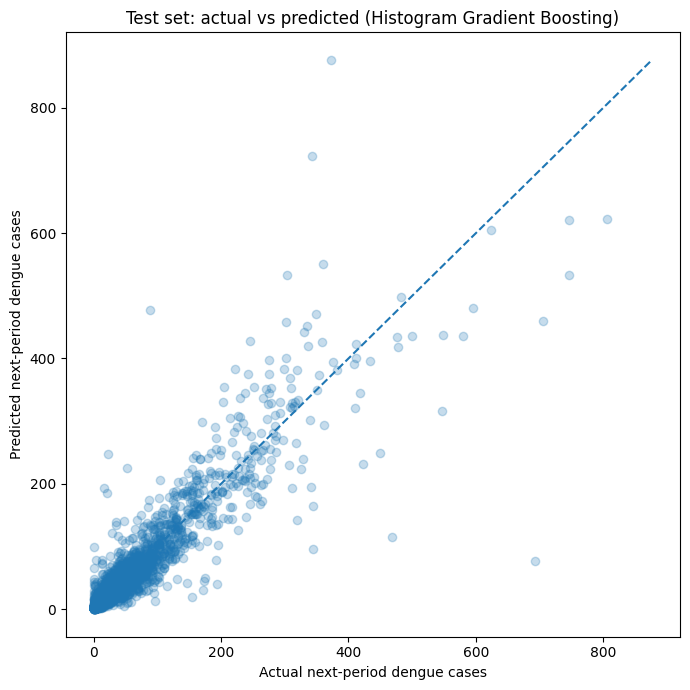

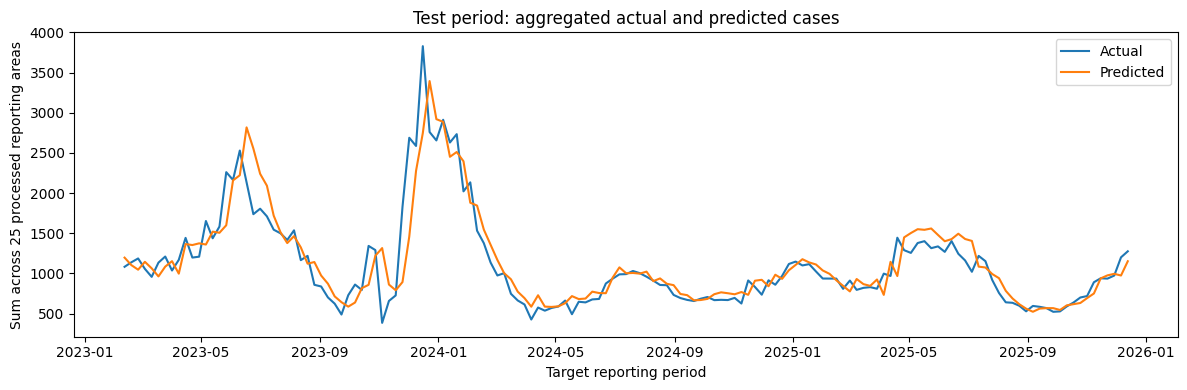

In [13]:
plt.figure(figsize=(7, 7))
plt.scatter(test_output["target_next_cases"], test_output["predicted_cases"], alpha=0.25)
max_value = max(test_output["target_next_cases"].max(), test_output["predicted_cases"].max())
plt.plot([0, max_value], [0, max_value], linestyle="--")
plt.xlabel("Actual next-period dengue cases")
plt.ylabel("Predicted next-period dengue cases")
plt.title(f"Test set: actual vs predicted ({best_model_name})")
plt.tight_layout()
plt.show()

plt.figure(figsize=(12, 4))
sample = test_output.sort_values("target_week_start").groupby("target_week_start", as_index=False).agg(
    actual_total=("target_next_cases", "sum"),
    predicted_total=("predicted_cases", "sum")
)
plt.plot(sample["target_week_start"], sample["actual_total"], label="Actual")
plt.plot(sample["target_week_start"], sample["predicted_total"], label="Predicted")
plt.xlabel("Target reporting period")
plt.ylabel("Sum across 25 processed reporting areas")
plt.title("Test period: aggregated actual and predicted cases")
plt.legend()
plt.tight_layout()
plt.show()

## 14. Save the final model and run manifest

The selected machine-learning model is saved as a joblib artifact. If a simple baseline is selected, no machine-learning artifact is saved; the selected baseline and its metrics are recorded in the manifest.

The manifest records the forecast origin/target definition, feature set, source-weather note, and chronological evaluation windows.


In [14]:
import json
import joblib

if final_model is not None:
    joblib.dump(
        final_model,
        OUTPUT_DIR / "selected_dengue_forecast_model.joblib"
    )

manifest = {
    "notebook": "06_dengue_case_forecasting.ipynb",
    "input_file": str(DATA_PATH),
    "rows_in_source": int(len(df)),
    "number_of_reporting_areas": int(df["district_key"].nunique()),
    "first_reporting_period": str(df["week_start"].min().date()),
    "last_reporting_period": str(df["week_end"].max().date()),
    "forecast_origin": "latest completed reporting period t",
    "forecast_target": "dengue_cases in next reporting period t+1",
    "dengue_history_features": [
        "dengue_current_period", "dengue_lag_1", "dengue_lag_2",
        "dengue_lag_3", "dengue_lag_4", "dengue_lag_51",
        "dengue_lag_52", "dengue_rolling_mean_4"
    ],
    "weather_lags": ["lag0_current_completed_period", "lag1_previous_completed_period"],
    "weather_availability_assumption": (
        "Current-period weather summaries must be available by forecast issuance; "
        "verify operational publication timing before deployment."
    ),
    "biological_lag_limitation": (
        "Reporting-period aggregates do not identify an exact 4-5 day biological delay."
    ),
    "seasonal_baseline_note": (
        "51 reporting-record lags are an approximate prior-year target-period comparison "
        "under a regular 52-period annual cadence, not exact calendar-week matching."
    ),
    "weather_source_note": "Current project weather data is Open-Meteo ERA5, not NASA POWER.",
    "geography_note": "25 reporting areas; Ampara/Kalmune combination remains a documented assumption.",
    "features": feature_cols,
    "train_target_end": str(train["target_week_start"].max().date()),
    "validation_target_start": str(valid["target_week_start"].min().date()),
    "validation_target_end": str(valid["target_week_start"].max().date()),
    "test_target_start": str(test["target_week_start"].min().date()),
    "test_target_end": str(test["target_week_start"].max().date()),
    "weather_ablation_results_file": "weather_ablation_comparison.csv",
    "weather_ablation_method": (
        "Histogram Gradient Boosting with identical hyperparameters and "
        "chronological splits, compared with and without weather predictors."
    ),
    "weather_ablation_test_without_weather_MAE": float(
        weather_ablation_results.loc[
            (weather_ablation_results["experiment"] == "Without weather") &
            (weather_ablation_results["evaluation"] == "test"), "MAE"
        ].iloc[0]
    ),
    "weather_ablation_test_with_weather_MAE": float(
        weather_ablation_results.loc[
            (weather_ablation_results["experiment"] == "With weather") &
            (weather_ablation_results["evaluation"] == "test"), "MAE"
        ].iloc[0]
    ),
    "selected_model": best_model_name,
    "test_MAE": float(test_metrics.loc[0, "MAE"]),
    "test_RMSE": float(test_metrics.loc[0, "RMSE"]),
}

with open(
    OUTPUT_DIR / "forecast_run_manifest.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(manifest, f, indent=2)

print("Notebook 06 completed.")
print("Forecasting outputs saved to:", OUTPUT_DIR)

display(pd.DataFrame([{
    "weather_ablation_results_file": "weather_ablation_comparison.csv",
    "weather_ablation_method": (
        "Histogram Gradient Boosting with identical hyperparameters and "
        "chronological splits, compared with and without weather predictors."
    ),
    "weather_ablation_test_without_weather_MAE": float(
        weather_ablation_results.loc[
            (weather_ablation_results["experiment"] == "Without weather") &
            (weather_ablation_results["evaluation"] == "test"), "MAE"
        ].iloc[0]
    ),
    "weather_ablation_test_with_weather_MAE": float(
        weather_ablation_results.loc[
            (weather_ablation_results["experiment"] == "With weather") &
            (weather_ablation_results["evaluation"] == "test"), "MAE"
        ].iloc[0]
    ),
    "selected_model": best_model_name,
    "test_MAE": test_metrics.loc[0, "MAE"],
    "test_RMSE": test_metrics.loc[0, "RMSE"],
    "output_folder": str(OUTPUT_DIR),
}]))


Notebook 06 completed.
Forecasting outputs saved to: c:\Users\Nethmi\Documents\GitHub\RiskWeave\outputs\forecasting


,weather_ablation_results_file,weather_ablation_method,weather_ablation_test_without_weather_MAE,weather_ablation_test_with_weather_MAE,selected_model,test_MAE,test_RMSE,output_folder
0,weather_ablation_comparison.csv,Histogram Gradient Boosting with identical hyp...,12.384966,12.537762,Histogram Gradient Boosting,12.537762,29.769481,c:\Users\Nethmi\Documents\GitHub\RiskWeave\out...


## 15. Interpretation checklist

Before reporting these results academically, answer:

1. Did the selected model outperform the persistence and recent-average baselines on validation and test?
2. Are errors concentrated in particular reporting areas?
3. Does the model systematically underpredict high-count periods (especially outbreak peaks)?
4. Is the forecast-time assumption realistic given when dengue reports and weather summaries are published?
5. Would the Ampara/Kalmune aggregation affect interpretation?
6. Does the model need rolling-origin evaluation in addition to this single chronological holdout?
7. Are reporting periods consistently spaced? A lag represents the previous record, so inspect the reporting-date-gap audit.
8. Does the approximate 51-record seasonal baseline align adequately with the actual reporting calendar?

**Do not claim that weather improves forecasting yet.** To test that claim fairly, compare:
- dengue-history + calendar features, and
- dengue-history + calendar + lagged weather features,

using exactly the same chronological splits and model settings. This controlled comparison is not silently assumed by this first notebook.

The current weather predictors are candidate weekly/reporting-period exposures. They do not establish an exact 4–5-day biological delay. Also verify that current-period weather (`lag0`) is available by the real forecast issuance time.

The next development step after reviewing these outputs is a controlled weather-ablation experiment and rolling time-based backtesting, followed by uncertainty evaluation and explainability.


In [1]:
# Inspect preprocessing-related variables

for name, obj in globals().copy().items():
    if any(
        term in name.lower()
        for term in [
            "imput",
            "pipeline",
            "preprocess",
            "numeric",
            "categorical",
            "model"
        ]
    ):
        if not name.startswith("_"):
            print(name, type(obj))